# Day 4 – Delivery Time Prediction
## Uber Eats Operational & Customer Intelligence System

**Objective:** Build and compare supervised regression models to predict delivery duration using the synthetic Uber Eats datasets.

### Models
- Baseline: `DummyRegressor`
- Linear regression baseline
- Ridge Regression
- Lasso Regression
- Random Forest Regressor

### Evaluation
MAE, RMSE, R², cross-validation, actual-vs-predicted plots, residual analysis, and feature importance.

> **Important:** This notebook uses synthetic data. Results demonstrate the workflow and should not be interpreted as real Uber Eats operational performance. The notebook attempts to identify common column-name variants, but review the detected schema before interpreting results.

## 1. Imports and project paths

Run this notebook from the project's `notebooks/` directory. The relative paths below match the project structure:
- `data/synthetic/`
- `data/processed/`
- `reports/figures/`

In [ ]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42

PROJECT_ROOT = Path("..").resolve()
DATA_DIR = PROJECT_ROOT / "data" / "synthetic"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Synthetic data directory exists:", DATA_DIR.exists())
print("Available CSV files:", [p.name for p in DATA_DIR.glob("*.csv")])

Project root: /home/nineleaps/uber-eats-intelligence
Synthetic data directory exists: True
Available CSV files: ['reviews.csv', 'customers.csv', 'restaurants.csv', 'orders.csv', 'deliveries.csv', 'drivers.csv', 'payments.csv']


## 2. Load the synthetic datasets

We load the tables that may contain delivery outcomes and explanatory features. Missing files are skipped so the notebook can still inspect whichever project files are available.

In [2]:
tables = {}
for filename in [
    "orders.csv", "deliveries.csv", "restaurants.csv",
    "drivers.csv", "customers.csv", "payments.csv", "reviews.csv"
]:
    path = DATA_DIR / filename
    if path.exists():
        tables[filename.replace(".csv", "")] = pd.read_csv(path)
        print(f"{filename}: {tables[filename.replace('.csv', '')].shape}")
    else:
        print(f"Not found (optional): {filename}")

if not tables:
    raise FileNotFoundError(
        f"No CSV files found in {DATA_DIR}. "
        "Check that the notebook is saved inside the project's notebooks/ folder."
    )

for name, df in tables.items():
    print(f"\n{name} columns:")
    print(df.columns.tolist())

orders.csv: (10000, 14)
deliveries.csv: (9358, 6)
restaurants.csv: (100, 6)
drivers.csv: (200, 4)
customers.csv: (1000, 5)
payments.csv: (10000, 6)
reviews.csv: (7000, 7)

orders columns:
['order_id', 'customer_id', 'restaurant_id', 'order_timestamp', 'order_amount', 'number_of_items', 'delivery_distance_km', 'prep_time_minutes', 'delivery_time_minutes', 'traffic', 'weather', 'is_weekend', 'peak_period_weight', 'order_status']

deliveries columns:
['delivery_id', 'order_id', 'driver_id', 'delivery_distance_km', 'delivery_time_minutes', 'delivery_status']

restaurants columns:
['restaurant_id', 'restaurant_name', 'city', 'category', 'restaurant_rating', 'avg_prep_time_minutes']

drivers columns:
['driver_id', 'vehicle_type', 'experience_months', 'driver_rating']

customers columns:
['customer_id', 'age', 'city', 'membership', 'signup_date']

payments columns:
['payment_id', 'order_id', 'payment_method', 'order_amount', 'tip_amount', 'payment_status']

reviews columns:
['review_id', 'ord

## 3. Inspect the delivery table and target column

The target is delivery duration in minutes. If the dataset already contains a duration column, it will be used. Otherwise, the notebook tries to calculate it from actual pickup and delivery timestamps.

The code prints the selected target so you can verify it matches your generated schema.

In [3]:
def normalize_name(name):
    return "".join(ch.lower() for ch in str(name) if ch.isalnum())

def find_column(df, candidates):
    lookup = {normalize_name(c): c for c in df.columns}
    for candidate in candidates:
        key = normalize_name(candidate)
        if key in lookup:
            return lookup[key]
    # relaxed matching for common variants
    for candidate in candidates:
        key = normalize_name(candidate)
        for normalized, original in lookup.items():
            if key and (key in normalized or normalized in key):
                return original
    return None

delivery_candidates = []
for table_name in ["deliveries", "orders"]:
    if table_name in tables:
        delivery_candidates.append((table_name, tables[table_name]))

if not delivery_candidates:
    raise ValueError("Neither deliveries.csv nor orders.csv was found.")

# Prefer deliveries table because it is the most likely source of actual delivery duration.
base_name, base = next(
    ((name, df) for name, df in delivery_candidates if name == "deliveries"),
    delivery_candidates[0]
)
df = base.copy()
print("Initial modeling table:", base_name, df.shape)
print("Columns:", df.columns.tolist())

target_candidates = [
    "delivery_time_minutes", "delivery_duration_minutes",
    "delivery_duration", "delivery_time", "duration_minutes",
    "actual_delivery_minutes", "total_delivery_minutes"
]
target_col = find_column(df, target_candidates)

if target_col is None:
    pickup_col = find_column(df, [
        "actual_pickup_time", "pickup_time", "picked_up_at",
        "pickup_timestamp", "actual_pickup"
    ])
    delivered_col = find_column(df, [
        "actual_delivery_time", "delivered_at", "delivery_timestamp",
        "delivered_time", "actual_delivery"
    ])
    if pickup_col and delivered_col:
        pickup = pd.to_datetime(df[pickup_col], errors="coerce")
        delivered = pd.to_datetime(df[delivered_col], errors="coerce")
        df["delivery_time_minutes"] = (delivered - pickup).dt.total_seconds() / 60
        target_col = "delivery_time_minutes"
        print(f"Calculated target from {pickup_col} and {delivered_col}.")
    else:
        raise ValueError(
            "Could not detect a delivery-duration target or a pair of pickup/delivery timestamps. "
            "Inspect the printed columns and update target_candidates/pickup candidates."
        )

df[target_col] = pd.to_numeric(df[target_col], errors="coerce")
print("Selected target:", target_col)
display(df.head())
display(df[[target_col]].describe())

Initial modeling table: deliveries (9358, 6)
Columns: ['delivery_id', 'order_id', 'driver_id', 'delivery_distance_km', 'delivery_time_minutes', 'delivery_status']
Selected target: delivery_time_minutes


,delivery_id,order_id,driver_id,delivery_distance_km,delivery_time_minutes,delivery_status
0,DL00001,O00001,D004,2.73,38,Delivered
1,DL00002,O00002,D003,3.09,40,Delivered
2,DL00003,O00003,D005,5.07,56,Delivered
3,DL00004,O00004,D048,3.84,30,Delivered
4,DL00005,O00005,D184,3.16,58,Delivered


,delivery_time_minutes
count,9358.000000
mean,50.708057
std,16.560654
min,10.000000
25%,39.000000
50%,50.000000
75%,61.000000
max,140.000000


## 4. Add relevant features from other tables

Join tables only when a shared key is found. To reduce accidental row multiplication, the right-hand table is deduplicated by the selected key before joining. After joining, check row counts and duplicated records.

Potential predictors include distance, order amount, item count, preparation time, traffic, weather, time of day, day of week, restaurant rating, restaurant category, and customer/restaurant identifiers.

In [4]:
def find_join_key(left, right):
    common_priority = [
        "order_id", "restaurant_id", "driver_id", "customer_id",
        "delivery_id", "payment_id"
    ]
    left_map = {normalize_name(c): c for c in left.columns}
    right_map = {normalize_name(c): c for c in right.columns}
    for key in common_priority:
        nk = normalize_name(key)
        if nk in left_map and nk in right_map:
            return left_map[nk], right_map[nk]
    return None, None

for table_name in ["orders", "restaurants", "drivers", "customers", "payments"]:
    if table_name not in tables or table_name == base_name:
        continue
    right = tables[table_name].copy()
    left_key, right_key = find_join_key(df, right)
    if left_key is None:
        print(f"Skipped {table_name}: no shared join key detected.")
        continue

    # Avoid bringing in a duplicate target from another table.
    right = right.drop_duplicates(subset=[right_key], keep="first")
    before = len(df)
    overlapping = (set(df.columns) & set(right.columns)) - {left_key, right_key}
    if overlapping:
        right = right.rename(columns={c: f"{table_name}_{c}" for c in overlapping})
    df = df.merge(
        right, left_on=left_key, right_on=right_key,
        how="left", suffixes=("", f"_{table_name}")
    )
    print(f"Joined {table_name} on {left_key}; rows {before} -> {len(df)}")

print("Modeling table after joins:", df.shape)
display(df.head())

Joined orders on order_id; rows 9358 -> 9358
Joined restaurants on restaurant_id; rows 9358 -> 9358
Joined drivers on driver_id; rows 9358 -> 9358
Joined customers on customer_id; rows 9358 -> 9358
Joined payments on order_id; rows 9358 -> 9358
Modeling table after joins: (9358, 36)


,delivery_id,order_id,driver_id,delivery_distance_km,delivery_time_minutes,delivery_status,customer_id,restaurant_id,order_timestamp,order_amount,...,driver_rating,age,customers_city,membership,signup_date,payment_id,payment_method,payments_order_amount,tip_amount,payment_status
0,DL00001,O00001,D004,2.73,38,Delivered,C0568,R064,2026-01-22 21:53:00,453.07,...,4.7,29,Mumbai,Regular,2025-05-29,P00001,Wallet,453.07,56.50,Paid
1,DL00002,O00002,D003,3.09,40,Delivered,C0500,R074,2026-06-24 20:16:00,357.08,...,4.5,38,Delhi,Gold,2024-09-09,P00002,Card,357.08,58.66,Paid
2,DL00003,O00003,D005,5.07,56,Delivered,C0746,R084,2026-04-03 03:15:00,1100.53,...,4.4,35,Delhi,Gold,2024-08-11,P00003,Card,1100.53,159.41,Paid
3,DL00004,O00004,D048,3.84,30,Delivered,C0749,R100,2026-04-10 13:00:00,509.76,...,4.1,33,Delhi,Regular,2025-09-24,P00004,UPI,509.76,29.79,Paid
4,DL00005,O00005,D184,3.16,58,Delivered,C0017,R019,2026-03-16 11:02:00,659.16,...,3.6,42,Bengaluru,Gold,2024-07-16,P00005,Cash,659.16,20.63,Paid


## 5. Data quality checks and feature engineering

We remove missing or invalid target rows and inspect extreme values. We do not silently remove target outliers; instead, we visualize them and apply a broad plausibility filter only when the data clearly contains impossible durations. Review the printed summary before proceeding.

In [5]:
print("Missing target values:", int(df[target_col].isna().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

df = df.dropna(subset=[target_col]).copy()
df = df.replace([np.inf, -np.inf], np.nan)

print("Target summary before plausibility filter:")
display(df[target_col].describe(percentiles=[.01, .05, .5, .95, .99]))

# A duration should be positive. Values above 6 hours are flagged as extreme for delivery-time
# modeling; inspect the count before filtering. This threshold is a modeling assumption.
invalid_duration = (df[target_col] <= 0) | (df[target_col] > 360)
print("Rows with non-positive or >360-minute target:", int(invalid_duration.sum()))
df = df.loc[~invalid_duration].copy()

# Create time features from a likely order timestamp, if available.
timestamp_col = find_column(df, [
    "order_timestamp", "order_time", "created_at", "order_date",
    "created_time", "placed_at"
])
if timestamp_col:
    ts = pd.to_datetime(df[timestamp_col], errors="coerce")
    if ts.notna().sum() > 0:
        df["order_hour"] = ts.dt.hour
        df["order_day_of_week"] = ts.dt.dayofweek
        df["order_is_weekend"] = (ts.dt.dayofweek >= 5).astype(float)
        print("Created time features from:", timestamp_col)

# Numeric coercion for columns that are mostly numeric strings.
for col in df.columns:
    if col == target_col:
        continue
    if df[col].dtype == "object":
        converted = pd.to_numeric(df[col], errors="coerce")
        nonmissing_original = df[col].notna().sum()
        if nonmissing_original and converted.notna().sum() / nonmissing_original >= 0.85:
            df[col] = converted

print("Rows after target cleaning:", len(df))
display(df[target_col].describe())

Missing target values: 0
Duplicate rows: 0
Target summary before plausibility filter:


count    9358.000000
mean       50.708057
std        16.560654
min        10.000000
1%         18.000000
5%         25.000000
50%        50.000000
95%        80.000000
99%        95.000000
max       140.000000
Name: delivery_time_minutes, dtype: float64

Rows with non-positive or >360-minute target: 0
Created time features from: order_timestamp
Rows after target cleaning: 9358


count    9358.000000
mean       50.708057
std        16.560654
min        10.000000
25%        39.000000
50%        50.000000
75%        61.000000
max       140.000000
Name: delivery_time_minutes, dtype: float64

## 6. Exploratory data analysis (EDA)

Inspect the target distribution, possible outliers, numeric correlations, and relationships between delivery time and candidate numeric predictors.

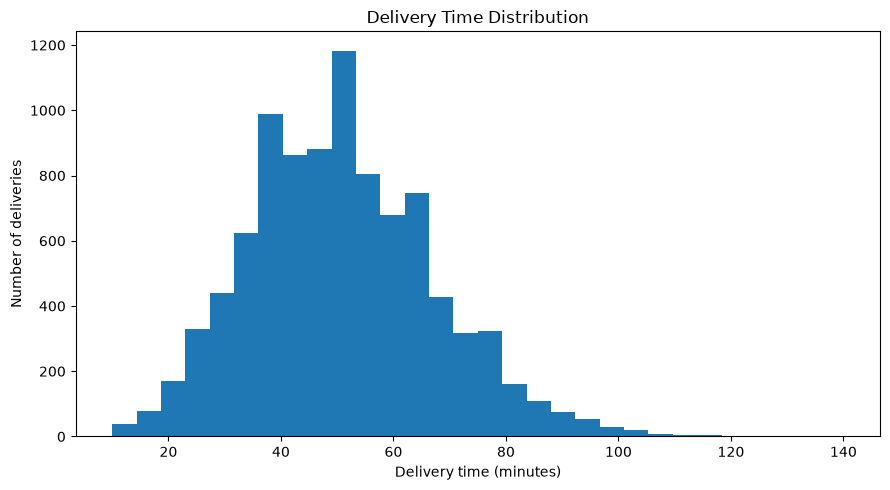

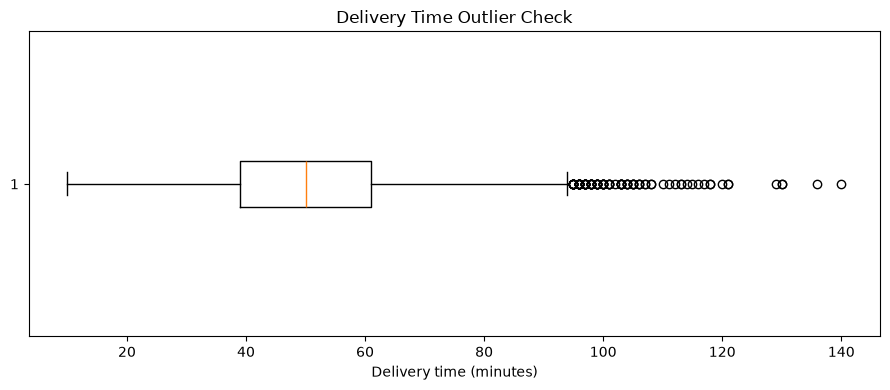

Correlations with target (lowest to highest):


,correlation_with_delivery_time
peak_period_weight,-0.002753
driver_rating,-0.002014
experience_months,-0.001970
age,0.002932
order_day_of_week,0.003344
is_weekend,0.008038
order_is_weekend,0.008038
restaurant_rating,0.008950
tip_amount,0.009951
number_of_items,0.011931


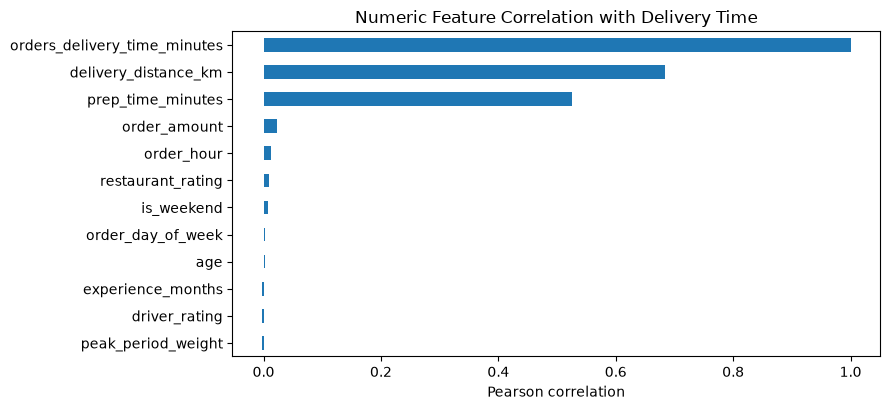

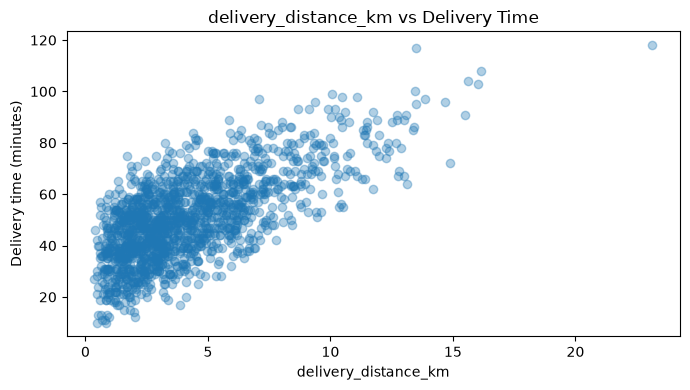

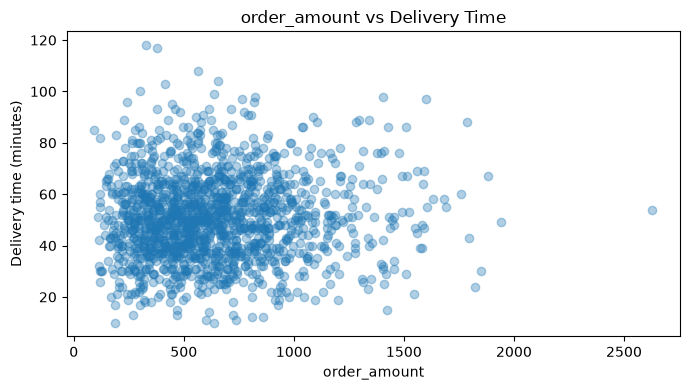

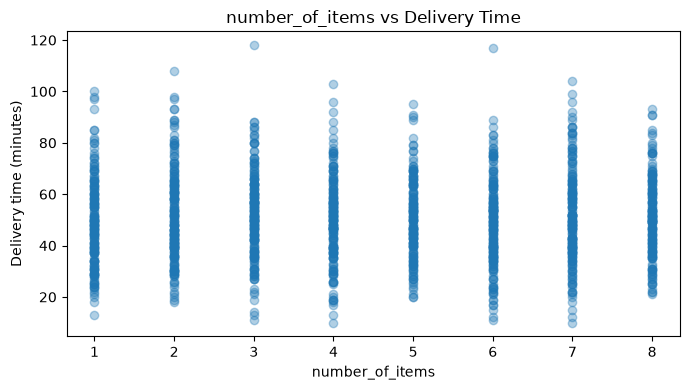

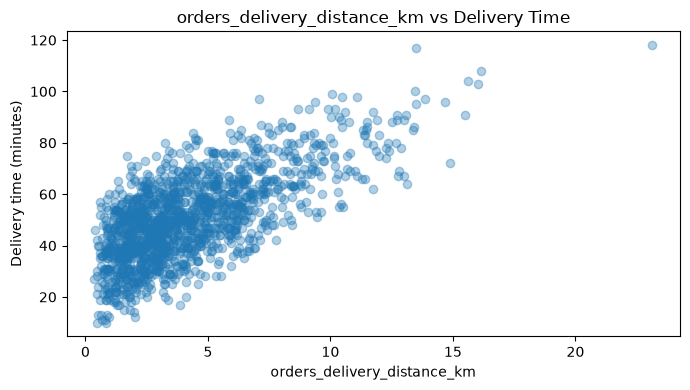

In [6]:
plt.figure(figsize=(9, 5))
plt.hist(df[target_col].dropna(), bins=30)
plt.title("Delivery Time Distribution")
plt.xlabel("Delivery time (minutes)")
plt.ylabel("Number of deliveries")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "day4_delivery_time_distribution.png", dpi=150)
plt.show()

plt.figure(figsize=(9, 4))
plt.boxplot(df[target_col].dropna(), vert=False)
plt.title("Delivery Time Outlier Check")
plt.xlabel("Delivery time (minutes)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "day4_delivery_time_boxplot.png", dpi=150)
plt.show()

numeric_df = df.select_dtypes(include=np.number)
corr = numeric_df.corr(numeric_only=True)
if target_col in corr.columns:
    target_corr = corr[target_col].drop(target_col).dropna().sort_values()
    print("Correlations with target (lowest to highest):")
    display(target_corr.to_frame("correlation_with_delivery_time"))

    if len(target_corr):
        top_corr = pd.concat([target_corr.head(8), target_corr.tail(8)]).drop_duplicates()
        plt.figure(figsize=(9, max(4, len(top_corr) * 0.35)))
        top_corr.sort_values().plot(kind="barh")
        plt.title("Numeric Feature Correlation with Delivery Time")
        plt.xlabel("Pearson correlation")
        plt.tight_layout()
        plt.savefig(FIGURE_DIR / "day4_target_correlations.png", dpi=150)
        plt.show()

candidate_scatter_cols = [
    c for c in numeric_df.columns
    if c != target_col and numeric_df[c].nunique(dropna=True) > 5
]
for col in candidate_scatter_cols[:4]:
    sample = df[[col, target_col]].dropna()
    if len(sample) > 1500:
        sample = sample.sample(1500, random_state=RANDOM_STATE)
    plt.figure(figsize=(7, 4))
    plt.scatter(sample[col], sample[target_col], alpha=0.35)
    plt.title(f"{col} vs Delivery Time")
    plt.xlabel(col)
    plt.ylabel("Delivery time (minutes)")
    plt.tight_layout()
    safe_col = "".join(ch if ch.isalnum() else "_" for ch in col)
    plt.savefig(FIGURE_DIR / f"day4_scatter_{safe_col}.png", dpi=150)
    plt.show()

## 7. Prepare the modeling features

We exclude the target and columns that directly reveal the answer (for example, actual delivery timestamps or another duration field). Identifier columns are excluded from the first model to reduce memorization. Numeric columns are imputed with the median; categorical columns are imputed with the most frequent value and one-hot encoded.

Review the selected features and excluded columns before training.

In [7]:
leakage_terms = [
    "deliverytime", "deliveryduration", "durationminutes",
    "actualdelivery", "deliveredat", "deliverytimestamp",
    "arrivalactual", "actualarrival"
]
identifier_terms = [
    "orderid", "deliveryid", "customerid", "driverid",
    "paymentid", "trackingid"
]

feature_cols = []
excluded_cols = {}
for col in df.columns:
    if col == target_col:
        excluded_cols[col] = "target"
        continue
    ncol = normalize_name(col)
    if any(term in ncol for term in leakage_terms):
        excluded_cols[col] = "possible target leakage"
        continue
    if any(term in ncol for term in identifier_terms):
        excluded_cols[col] = "identifier"
        continue
    if df[col].nunique(dropna=True) <= 1:
        excluded_cols[col] = "constant/empty"
        continue
    if pd.api.types.is_datetime64_any_dtype(df[col]):
        excluded_cols[col] = "raw datetime (derived features used if available)"
        continue
    feature_cols.append(col)

X = df[feature_cols].copy()
y = df[target_col].copy()

# Drop columns with too many distinct categories (typically free-text or near-unique IDs).
high_cardinality = [
    c for c in X.columns
    if X[c].dtype == "object" and X[c].nunique(dropna=True) > max(50, int(0.20 * len(X)))
]
if high_cardinality:
    print("Excluding high-cardinality categorical columns:", high_cardinality)
    X = X.drop(columns=high_cardinality)
    feature_cols = X.columns.tolist()

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

print("Target:", target_col)
print("Rows:", len(X))
print("Feature count:", X.shape[1])
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Excluded columns and reasons:", excluded_cols)

if X.shape[1] == 0:
    raise ValueError("No usable features remain. Inspect the feature exclusion rules and dataset columns.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

Target: delivery_time_minutes
Rows: 9358
Feature count: 29
Numeric features: ['delivery_distance_km', 'order_amount', 'number_of_items', 'orders_delivery_distance_km', 'prep_time_minutes', 'is_weekend', 'peak_period_weight', 'restaurant_rating', 'avg_prep_time_minutes', 'experience_months', 'driver_rating', 'age', 'payments_order_amount', 'tip_amount', 'order_hour', 'order_day_of_week', 'order_is_weekend']
Categorical features: ['restaurant_id', 'order_timestamp', 'traffic', 'weather', 'restaurant_name', 'city', 'category', 'vehicle_type', 'customers_city', 'membership', 'signup_date', 'payment_method']
Excluded columns and reasons: {'delivery_id': 'identifier', 'order_id': 'identifier', 'driver_id': 'identifier', 'delivery_time_minutes': 'target', 'delivery_status': 'constant/empty', 'customer_id': 'identifier', 'orders_delivery_time_minutes': 'possible target leakage', 'order_status': 'constant/empty', 'payment_id': 'identifier', 'payment_status': 'constant/empty'}
Train shape: (7486

## 8. Build preprocessing and regression pipelines

All imputing, scaling, and one-hot encoding are fitted inside the training pipeline to avoid data leakage. Ridge and Lasso benefit from scaling; Random Forest does not require it, but a shared preprocessor keeps comparisons consistent.

In [8]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

models = {
    "Dummy Baseline": DummyRegressor(strategy="median"),
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01, max_iter=10000),
    "Random Forest": RandomForestRegressor(
        n_estimators=250,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

pipelines = {
    name: Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    for name, model in models.items()
}

print("Prepared models:", list(pipelines.keys()))

Prepared models: ['Dummy Baseline', 'Linear Regression', 'Ridge Regression', 'Lasso Regression', 'Random Forest']


## 9. Train models and compare test-set performance

Metrics:
- **MAE:** average absolute prediction error in minutes; lower is better.
- **RMSE:** penalizes larger errors more strongly; lower is better.
- **R²:** proportion of target variance explained relative to a mean baseline; higher is generally better.

The test set is held out until this comparison step.

In [9]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

fitted_models = {}
predictions = {}
rows = []

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted_models[name] = pipe
    predictions[name] = pred
    rows.append({"Model": name, **regression_metrics(y_test, pred)})

comparison = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
display(comparison.round(4))

comparison.to_csv(PROCESSED_DIR / "day4_regression_model_comparison.csv", index=False)
best_model_name = comparison.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
best_predictions = predictions[best_model_name]

print("Best model by test MAE:", best_model_name)

,Model,MAE,RMSE,R2
0,Lasso Regression,4.0245,5.0325,0.9090
1,Ridge Regression,4.1966,5.2434,0.9012
2,Random Forest,4.3804,5.5065,0.8911
3,Linear Regression,4.5240,5.6341,0.8860
4,Dummy Baseline,13.2046,16.7738,-0.0109


Best model by test MAE: Lasso Regression


## 10. Cross-validation on the training data

Use shuffled K-fold cross-validation on the training set only. This estimates performance variability without using the held-out test set for model selection. For a real production system with time-ordered data, use a time-aware validation design instead.

In [10]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

for name, pipe in pipelines.items():
    scores = cross_validate(
        pipe, X_train, y_train, cv=cv, scoring=scoring,
        n_jobs=-1, error_score="raise"
    )
    cv_rows.append({
        "Model": name,
        "CV_MAE_mean": -scores["test_MAE"].mean(),
        "CV_MAE_std": scores["test_MAE"].std(),
        "CV_RMSE_mean": -scores["test_RMSE"].mean(),
        "CV_RMSE_std": scores["test_RMSE"].std(),
        "CV_R2_mean": scores["test_R2"].mean(),
        "CV_R2_std": scores["test_R2"].std()
    })

cv_comparison = pd.DataFrame(cv_rows).sort_values("CV_MAE_mean").reset_index(drop=True)
display(cv_comparison.round(4))
cv_comparison.to_csv(PROCESSED_DIR / "day4_cross_validation_results.csv", index=False)

,Model,CV_MAE_mean,CV_MAE_std,CV_RMSE_mean,CV_RMSE_std,CV_R2_mean,CV_R2_std
0,Lasso Regression,4.0112,0.0955,5.0328,0.1122,0.9071,0.0046
1,Ridge Regression,4.1696,0.0939,5.2379,0.1045,0.8994,0.0044
2,Linear Regression,4.3670,0.1135,5.4926,0.1134,0.8894,0.0050
3,Random Forest,4.3958,0.0745,5.5438,0.1195,0.8873,0.0054
4,Dummy Baseline,13.0465,0.1939,16.5996,0.2704,-0.0092,0.0051


## 11. Actual vs predicted and residual analysis

A strong model should place predictions near the diagonal in the actual-versus-predicted plot. Residuals (actual minus predicted) should not show a strong systematic pattern.

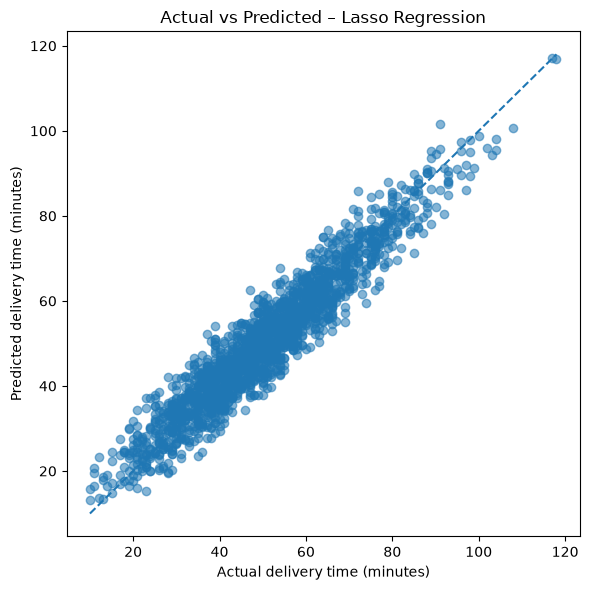

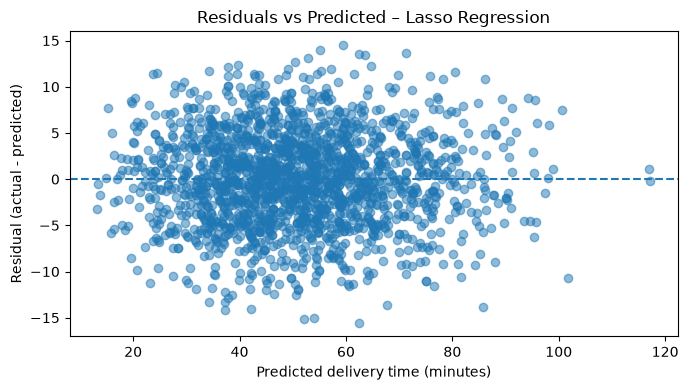

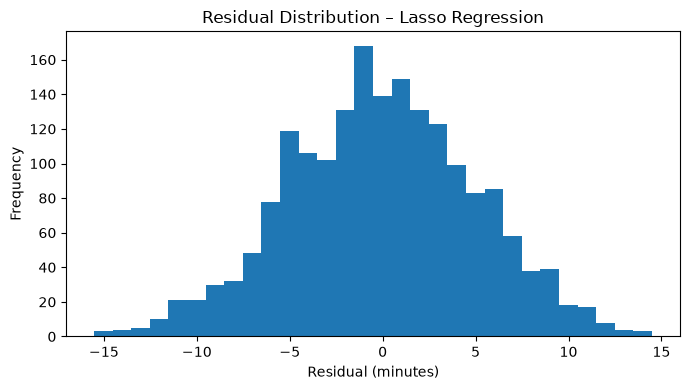

In [11]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_predictions, alpha=0.55)
min_val = min(float(y_test.min()), float(np.min(best_predictions)))
max_val = max(float(y_test.max()), float(np.max(best_predictions)))
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")
plt.title(f"Actual vs Predicted – {best_model_name}")
plt.xlabel("Actual delivery time (minutes)")
plt.ylabel("Predicted delivery time (minutes)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "day4_actual_vs_predicted.png", dpi=150)
plt.show()

residuals = y_test.to_numpy() - best_predictions
plt.figure(figsize=(7, 4))
plt.scatter(best_predictions, residuals, alpha=0.5)
plt.axhline(0, linestyle="--")
plt.title(f"Residuals vs Predicted – {best_model_name}")
plt.xlabel("Predicted delivery time (minutes)")
plt.ylabel("Residual (actual - predicted)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "day4_residual_plot.png", dpi=150)
plt.show()

plt.figure(figsize=(7, 4))
plt.hist(residuals, bins=30)
plt.title(f"Residual Distribution – {best_model_name}")
plt.xlabel("Residual (minutes)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "day4_residual_distribution.png", dpi=150)
plt.show()

## 12. Feature importance

For Random Forest, report built-in impurity-based importance. For the selected model, permutation importance on the held-out test set gives a model-agnostic view of which original input columns matter most. Permutation importance can be noisy on small or highly correlated datasets.

,feature,importance
3,num__orders_delivery_distance_km,0.250459
0,num__delivery_distance_km,0.236439
8,num__avg_prep_time_minutes,0.143550
4,num__prep_time_minutes,0.141177
7516,cat__traffic_High,0.080911
7521,cat__weather_Rainy,0.039405
7517,cat__traffic_Low,0.010682
7519,cat__weather_Clear,0.010106
7518,cat__traffic_Medium,0.009536
9,num__experience_months,0.007212


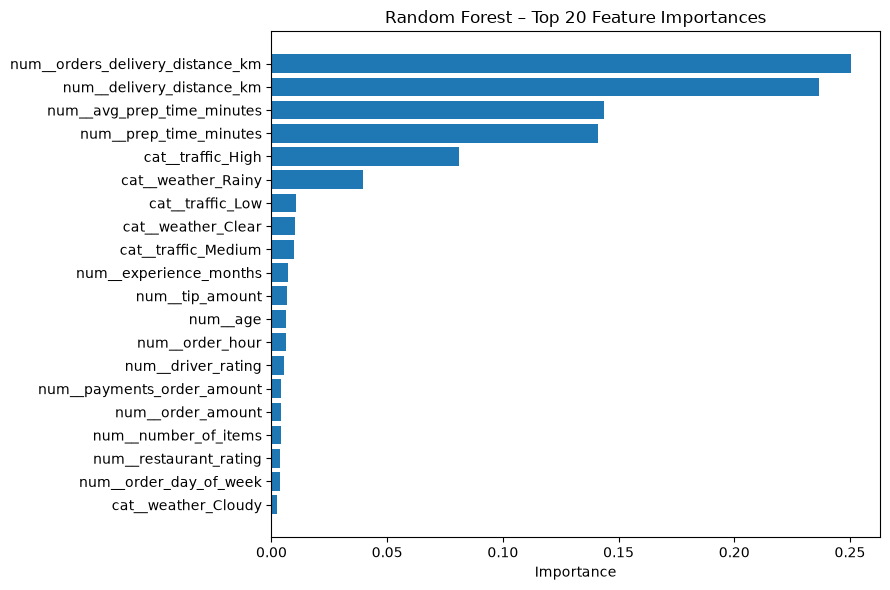

,feature,importance_mean,importance_std
0,delivery_distance_km,8.7229,0.1380
6,prep_time_minutes,6.6666,0.1302
7,traffic,3.3854,0.1154
8,weather,1.9718,0.0540
23,payment_method,0.0022,0.0021
3,order_amount,0.0012,0.0007
11,restaurant_name,0.0004,0.0004
10,peak_period_weight,0.0001,0.0002
18,driver_rating,0.0000,0.0001
5,orders_delivery_distance_km,0.0000,0.0000


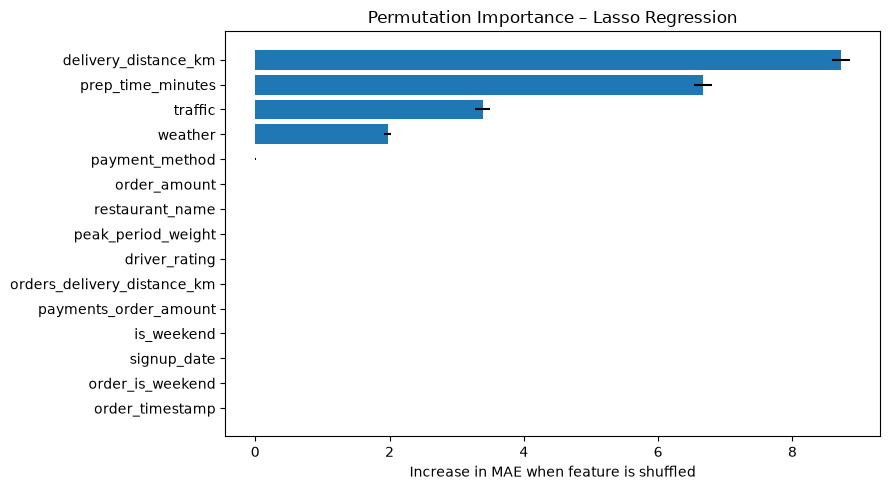

In [12]:
# Random Forest built-in importance, when available.
rf_pipe = fitted_models.get("Random Forest")
if rf_pipe is not None:
    rf_model = rf_pipe.named_steps["model"]
    transformed_names = rf_pipe.named_steps["preprocessor"].get_feature_names_out()
    rf_importance = pd.DataFrame({
        "feature": transformed_names,
        "importance": rf_model.feature_importances_
    }).sort_values("importance", ascending=False).head(20)
    display(rf_importance)

    plt.figure(figsize=(9, 6))
    plot_data = rf_importance.sort_values("importance")
    plt.barh(plot_data["feature"], plot_data["importance"])
    plt.title("Random Forest – Top 20 Feature Importances")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "day4_random_forest_feature_importance.png", dpi=150)
    plt.show()
    rf_importance.to_csv(PROCESSED_DIR / "day4_random_forest_feature_importance.csv", index=False)

perm = permutation_importance(
    best_model, X_test, y_test,
    n_repeats=8, random_state=RANDOM_STATE,
    scoring="neg_mean_absolute_error", n_jobs=-1
)
perm_importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)
display(perm_importance.head(15).round(4))

perm_importance.to_csv(PROCESSED_DIR / "day4_permutation_importance.csv", index=False)

plt.figure(figsize=(9, 5))
plot_data = perm_importance.head(15).sort_values("importance_mean")
plt.barh(plot_data["feature"], plot_data["importance_mean"], xerr=plot_data["importance_std"])
plt.title(f"Permutation Importance – {best_model_name}")
plt.xlabel("Increase in MAE when feature is shuffled")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "day4_permutation_importance.png", dpi=150)
plt.show()

## 13. Overfitting check

Compare training and test metrics for the Random Forest. A much better training score than test score can indicate overfitting. This is a diagnostic, not a definitive test.

In [13]:
overfit_rows = []
for name in ["Ridge Regression", "Lasso Regression", "Random Forest"]:
    pipe = fitted_models[name]
    train_pred = pipe.predict(X_train)
    test_pred = pipe.predict(X_test)
    train_metrics = regression_metrics(y_train, train_pred)
    test_metrics = regression_metrics(y_test, test_pred)
    overfit_rows.append({
        "Model": name,
        "Train_MAE": train_metrics["MAE"],
        "Test_MAE": test_metrics["MAE"],
        "Train_R2": train_metrics["R2"],
        "Test_R2": test_metrics["R2"],
        "R2_gap_train_minus_test": train_metrics["R2"] - test_metrics["R2"]
    })

overfit_check = pd.DataFrame(overfit_rows).sort_values("Test_MAE")
display(overfit_check.round(4))
overfit_check.to_csv(PROCESSED_DIR / "day4_overfitting_check.csv", index=False)

,Model,Train_MAE,Test_MAE,Train_R2,Test_R2,R2_gap_train_minus_test
1,Lasso Regression,3.9896,4.0245,0.9082,0.9090,-0.0008
0,Ridge Regression,1.9268,4.1966,0.9785,0.9012,0.0772
2,Random Forest,1.8416,4.3804,0.9791,0.8911,0.0880


## 14. Save predictions and evaluation report

The notebook writes:
- Feature-engineered modeling data
- Model comparison and cross-validation tables
- Feature importance tables
- Test-set predictions
- A Markdown report with actual metrics and a cautious business interpretation

In [16]:
prediction_output = pd.DataFrame({
    "actual_delivery_time_minutes": y_test.to_numpy(),
    "predicted_delivery_time_minutes": best_predictions,
    "residual_minutes": y_test.to_numpy() - best_predictions
})
prediction_output.to_csv(PROCESSED_DIR / "day4_test_predictions.csv", index=False)

# Store a copy of the cleaned data used in this notebook.
df.to_csv(PROCESSED_DIR / "day4_feature_engineered_dataset.csv", index=False)

best_row = comparison.loc[comparison["Model"] == best_model_name].iloc[0]
best_cv_row = cv_comparison.loc[cv_comparison["Model"] == best_model_name].iloc[0]

report_lines = [
    "# Day 4 – Delivery Time Prediction: Evaluation Report",
    "",
    "## Dataset and target",
    f"- Modeling rows after target cleaning: {len(df)}",
    f"- Target column: `{target_col}`",
    f"- Number of model features: {X.shape[1]}",
    f"- Training rows: {len(X_train)}",
    f"- Test rows: {len(X_test)}",
    "",
    "## Test-set model comparison",
    comparison.to_markdown(index=False, floatfmt=".4f"),
    "",
    "## Cross-validation",
    cv_comparison.to_markdown(index=False, floatfmt=".4f"),
    "",
    "## Recommended model",
    f"- Best model by held-out test MAE: **{best_model_name}**",
    f"- MAE: {best_row['MAE']:.3f} minutes",
    f"- RMSE: {best_row['RMSE']:.3f} minutes",
    f"- R²: {best_row['R2']:.3f}",
    f"- Cross-validation mean MAE: {best_cv_row['CV_MAE_mean']:.3f} ± {best_cv_row['CV_MAE_std']:.3f} minutes",
    "",
    "## Business interpretation",
    f"The selected model's average absolute error is approximately {best_row['MAE']:.1f} minutes on the held-out test set. "
    "Use this error magnitude to judge whether the model could support delivery-time estimates. "
    "Review the permutation-importance table to identify features that appear most useful, and validate whether those features "
    "are available at the time a prediction would actually be made.",
    "",
    "## Limitations",
    "- The data is synthetic and may not represent real delivery behavior.",
    "- Some potential predictors may be missing or represented by simplified fields.",
    "- If a feature is only known after delivery, it must not be used for live predictions.",
    "- Random train/test split assumes rows are sufficiently independent; future production validation may need a time-based split.",
    "- Feature importance describes predictive association, not causation.",
    "",
    "## Generated outputs",
    "- `day4_regression_model_comparison.csv`",
    "- `day4_cross_validation_results.csv`",
    "- `day4_test_predictions.csv`",
    "- `day4_permutation_importance.csv`",
    "- `day4_feature_engineered_dataset.csv`",
    "- Figures in `reports/figures/` prefixed with `day4_`",
]
report_path = PROCESSED_DIR / "day4_regression_evaluation_report.md"
report_path.write_text("\n".join(report_lines), encoding="utf-8")
print("Saved report:", report_path)
print("Saved processed outputs to:", PROCESSED_DIR)

Saved report: /home/nineleaps/uber-eats-intelligence/data/processed/day4_regression_evaluation_report.md
Saved processed outputs to: /home/nineleaps/uber-eats-intelligence/data/processed
